# ThinPFN walkthrough

A prior-fitted network scores a new table from its labelled rows in one forward pass. This notebook runs the released
model on one public credit book, compares it with logistic regression and XGBoost at three context sizes, shows what the
inference recipe adds, and draws a synthetic table from the prior the network was trained on.

Requirements: `pip install -e ".[benchmark]"` and the book prepared with `python -m thinpfn.data.books prepare us_bureau`
(a 7 MB download from OpenML).

In [1]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
sys.path.insert(0, str(Path.cwd().parent) if Path.cwd().name == "notebooks" else str(Path.cwd()))
from thinpfn import ThinPFNClassifier, load_pretrained
from thinpfn.data import books
from thinpfn import baselines

BOOK = "us_bureau"   # Give Me Some Credit: 10 bureau features, 6 percent serious delinquency
Xtr, ytr = books.load(BOOK, "train"); Xv, yv = books.load(BOOK, "validation")
print(f"{BOOK}: {len(ytr)} training rows, {len(yv)} validation rows, {Xtr.shape[1]} features, prevalence {ytr.mean():.3f}")

us_bureau: 4000 training rows, 2000 validation rows, 10 features, prevalence 0.064


## 1. Score a book from 500 labelled rows

`fit` stores the context; nothing is trained. `predict_proba` is one forward pass of the pretrained network (eight passes
with the default column-permutation ensemble).

In [2]:
Xc, yc = books.subsample_context(Xtr, ytr, 500, seed=0)
clf = ThinPFNClassifier()
t0 = time.time(); clf.fit(Xc, yc); p = clf.predict_proba(Xv)[:, 1]; dt = time.time() - t0
print(f"AUC {roc_auc_score(yv, p):.3f} on {len(yv)} validation rows, {dt:.2f} s on {clf.model.head.weight.device}")

AUC 0.856 on 2000 validation rows, 1.23 s on cuda:0


## 2. Against logistic regression and XGBoost, at n = 200, 500, 1000

Each baseline is fitted on exactly the same context rows (XGBoost picks its configuration on a held-out slice of the
context, which is how a practitioner would tune it with this little data). Three context seeds per n.

In [3]:
rows = []
for n in (200, 500, 1000):
    for s in range(3):
        Xc, yc = books.subsample_context(Xtr, ytr, n, s)
        rows.append(dict(n=n, seed=s, ThinPFN=roc_auc_score(yv, ThinPFNClassifier().fit(Xc, yc).decision_function(Xv)),
                         Logistic=roc_auc_score(yv, baselines.logistic(Xc, yc, Xv, seed=s)), XGBoost=roc_auc_score(yv, baselines.xgboost(Xc, yc, Xv, seed=s))))
res = pd.DataFrame(rows).groupby("n")[["ThinPFN", "XGBoost", "Logistic"]].mean().round(3); res

,ThinPFN,XGBoost,Logistic
n,,,
200,0.833,0.797,0.817
500,0.849,0.828,0.754
1000,0.855,0.847,0.745


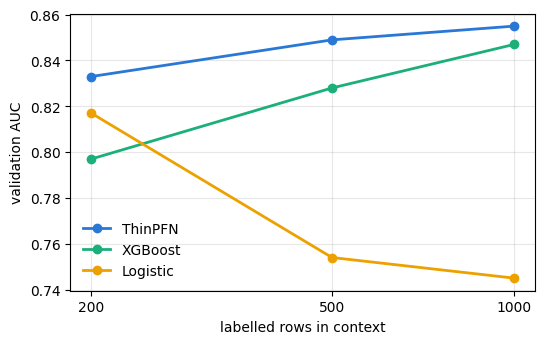

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for k, col in [("ThinPFN", "#2a78d6"), ("XGBoost", "#1baf7a"), ("Logistic", "#eda100")]:
    ax.plot(res.index, res[k], marker="o", lw=2, color=col, label=k)
ax.set_xscale("log"); ax.set_xticks([200, 500, 1000]); ax.set_xticklabels(["200", "500", "1000"]); ax.minorticks_off()
ax.set_xlabel("labelled rows in context"); ax.set_ylabel("validation AUC"); ax.legend(frameon=False); ax.grid(alpha=0.3); plt.show()

## 3. What the inference recipe adds

Same weights, three ways of calling them: plain z-scored inputs in a single pass, quantile-normal inputs, and
quantile-normal inputs averaged over eight column orders (the released default).

In [5]:
Xc, yc = books.subsample_context(Xtr, ytr, 1000, seed=0)
for label, kw in [("z-score, single pass", dict(preprocess="z", n_perm=0)), ("quantile-normal, single pass", dict(preprocess="qnorm", n_perm=0)), ("quantile-normal, 8 permutations", dict(preprocess="qnorm", n_perm=8))]:
    print(f"{label:34s} AUC {roc_auc_score(yv, ThinPFNClassifier(**kw).fit(Xc, yc).decision_function(Xv)):.3f}")

z-score, single pass               AUC 0.815


quantile-normal, single pass       AUC 0.863


quantile-normal, 8 permutations    AUC 0.866


## 4. A table from the prior

The network never saw a real row during pre-training. This is one draw from the credit ledger simulator: latent risk,
a Markov delinquency chain, application and bureau columns, a label on a horizon, NaN injection and nuisance columns.

In [6]:
from thinpfn.priors import credit_ledger
rng = np.random.default_rng(7); t = credit_ledger.sample(rng, n=400)
print(f"{t.n} rows, {t.d} columns, prevalence {t.y.mean():.3f}, context share {t.context.mean():.2f}, oracle AUC {t.meta.get('oracle_auc', float('nan')):.2f}, missing {np.isnan(t.X).mean():.1%}")
pd.DataFrame(t.X[:8], columns=[f"c{j}" for j in range(t.d)]).round(2).assign(y=t.y[:8], context=t.context[:8]).iloc[:, list(range(min(10, t.d))) + [-2, -1]]

400 rows, 34 columns, prevalence 0.083, context share 0.31, oracle AUC 0.86, missing 21.0%


,c0,c1,c2,c3,c4,c5,c6,c7,c8,c9,y,context
0,-0.57,-0.30,-1.0,-0.99,0.33,-0.34,0.0,0.0,-0.38,-0.49,0,False
1,NaN,NaN,NaN,NaN,NaN,-1.22,NaN,4.0,-0.18,NaN,0,True
2,0.42,-0.03,1.0,-0.10,-0.72,1.62,0.0,0.0,-0.54,-0.51,0,False
3,NaN,NaN,NaN,NaN,NaN,-0.34,NaN,3.0,0.66,NaN,0,False
4,-0.63,-0.37,-1.0,-0.96,0.82,0.39,0.0,2.0,-0.29,-0.59,1,True
5,-0.12,-0.38,-1.0,1.28,1.28,-0.79,-1.0,3.0,-0.48,1.03,1,False
6,-0.57,-0.49,-1.0,-1.07,0.34,-0.34,-2.0,3.0,-0.08,-0.48,0,True
7,NaN,NaN,NaN,NaN,NaN,0.39,NaN,0.0,-0.36,NaN,0,False


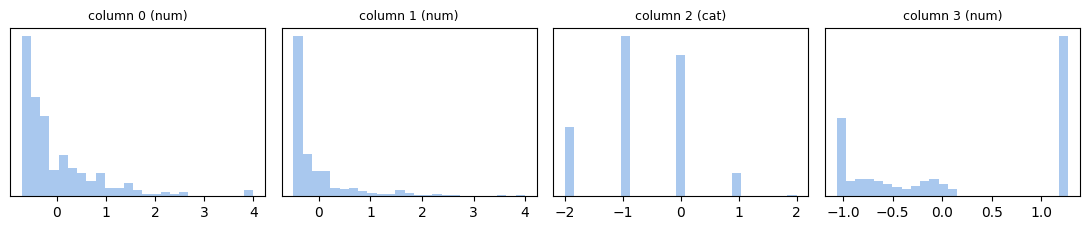

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.4))
for ax, j in zip(axes, range(4)):
    v = t.X[:, j]; v = v[np.isfinite(v)]; ax.hist(v, bins=25, color="#a9c8ee"); ax.set_title(f"column {j} ({'cat' if t.is_categorical[j] else 'num'})", fontsize=9); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 5. Your own data

```python
clf = ThinPFNClassifier().fit(train_df[features], train_df["label"])
scores = clf.predict_proba(new_df[features])[:, 1]
```

Pandas frames work directly (object columns are ordinal-encoded on the context, NaN is allowed). Keep the context between
200 and a few thousand rows and at most 64 features; above that a tuned boosted model with all the data is the better tool.